In [1]:
from google.colab import files
uploaded = files.upload()


Saving CrestLine_Loan_Portfolio_Practice_Dataset.zip to CrestLine_Loan_Portfolio_Practice_Dataset.zip


In [2]:

import zipfile
import os

zip_name = next(
    name for name in uploaded if name.endswith(".zip")
)

with zipfile.ZipFile(zip_name, "r") as z:
    z.extractall("/content/loan_data")

os.listdir("/content/loan_data")


['payments.csv',
 'accounts.csv',
 'customers.csv',
 'history.csv',
 'loans.csv',
 'README.txt']

In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

print("All libraries are ready!")


All libraries are ready!


In [4]:

folder = "/content/loan_data"

loans = pd.read_csv(f"{folder}/loans.csv")
customers = pd.read_csv(f"{folder}/customers.csv")
payments = pd.read_csv(f"{folder}/payments.csv")
accounts = pd.read_csv(f"{folder}/accounts.csv")
history = pd.read_csv(f"{folder}/history.csv")

print("Loans:", loans.shape)
print("Customers:", customers.shape)
print("Payments:", payments.shape)
print("Accounts:", accounts.shape)
print("History:", history.shape)


Loans: (500, 6)
Customers: (500, 4)
Payments: (6036, 8)
Accounts: (500, 4)
History: (500, 4)


In [5]:

datasets = {
    "Loans": loans,
    "Customers": customers,
    "Payments": payments,
    "Accounts": accounts,
    "History": history
}

for name, df in datasets.items():
    print("\n", name)
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print("Missing values:\n", df.isnull().sum())
    print("Duplicate rows:", df.duplicated().sum())
    display(df.head())



 Loans
Shape: (500, 6)
Columns: ['loan_id', 'customer_id', 'loan_type', 'amount', 'tenure_months', 'interest_rate']
Missing values:
 loan_id          0
customer_id      0
loan_type        0
amount           0
tenure_months    0
interest_rate    0
dtype: int64
Duplicate rows: 0


,loan_id,customer_id,loan_type,amount,tenure_months,interest_rate
0,L0001,C0001,Personal Loan,85399.15,48,6.92
1,L0002,C0002,Auto Loan,31815.35,48,11.63
2,L0003,C0003,Business Loan,11188.30,18,9.12
3,L0004,C0004,Auto Loan,28490.07,6,19.82
4,L0005,C0005,Personal Loan,11415.90,12,15.07



 Customers
Shape: (500, 4)
Columns: ['customer_id', 'income_band', 'occupation', 'region']
Missing values:
 customer_id     0
income_band    22
occupation      0
region          0
dtype: int64
Duplicate rows: 0


,customer_id,income_band,occupation,region
0,C0001,Upper-Middle,Business,North
1,C0002,Low,Salaried,South
2,C0003,Lower-Middle,Retired,Central
3,C0004,Upper-Middle,Retired,North
4,C0005,High,Salaried,North



 Payments
Shape: (6036, 8)
Columns: ['payment_id', 'loan_id', 'customer_id', 'due_date', 'paid_date', 'amount_due', 'amount_paid', 'status']
Missing values:
 payment_id       0
loan_id          0
customer_id      0
due_date         0
paid_date      203
amount_due       0
amount_paid      0
status           0
dtype: int64
Duplicate rows: 12


,payment_id,loan_id,customer_id,due_date,paid_date,amount_due,amount_paid,status
0,P000001,L0001,C0001,2025-05-13,2025-05-13,14479.43,14070.96,Paid
1,P000002,L0001,C0001,2025-06-13,2025-06-11,14479.43,14216.00,Paid
2,P000003,L0001,C0001,2025-07-13,2025-07-14,14479.43,14410.76,Paid
3,P000004,L0001,C0001,2025-08-13,2025-08-21,14479.43,11020.37,Late
4,P000005,L0001,C0001,2025-09-13,2025-10-07,14479.43,11063.61,Late



 Accounts
Shape: (500, 4)
Columns: ['account_id', 'customer_id', 'balance_band', 'relationship_years']
Missing values:
 account_id            0
customer_id           0
balance_band          0
relationship_years    0
dtype: int64
Duplicate rows: 0


,account_id,customer_id,balance_band,relationship_years
0,A0001,C0001,High,5
1,A0002,C0002,Medium,13
2,A0003,C0003,High,14
3,A0004,C0004,Medium,5
4,A0005,C0005,High,13



 History
Shape: (500, 4)
Columns: ['history_id', 'customer_id', 'past_delays', 'restructuring_flag']
Missing values:
 history_id            0
customer_id           0
past_delays           0
restructuring_flag    0
dtype: int64
Duplicate rows: 0


,history_id,customer_id,past_delays,restructuring_flag
0,H0001,C0001,1,No
1,H0002,C0002,2,No
2,H0003,C0003,0,No
3,H0004,C0004,1,Yes
4,H0005,C0005,0,No


In [6]:

# 1. Clean column names
for df in [loans, customers, payments, accounts, history]:
    df.columns = df.columns.str.strip()

# 2. Fill missing income bands
customers["income_band"] = (
    customers["income_band"]
    .replace(r"^\s*$", np.nan, regex=True)
    .fillna("Unknown")
)

# 3. Standardize loan type labels
loans["loan_type"] = (
    loans["loan_type"]
    .astype("string")
    .str.strip()
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.title()
)

# 4. Remove exact duplicate payment rows
before = len(payments)
payments = payments.drop_duplicates().copy()
print("Exact duplicate rows removed:", before - len(payments))

# 5. Convert payment dates
for col in ["due_date", "paid_date"]:
    payments[col] = pd.to_datetime(
        payments[col], errors="coerce"
    )

print("\nMissing values after cleaning:")
print("Customers:\n", customers.isnull().sum())
print("Payment dates:\n", payments[["due_date", "paid_date"]].isnull().sum())
print("Loan types:\n", loans["loan_type"].value_counts())


Exact duplicate rows removed: 12

Missing values after cleaning:
Customers:
 customer_id    0
income_band    0
occupation     0
region         0
dtype: int64
Payment dates:
 due_date       4
paid_date    207
dtype: int64
Loan types:
 loan_type
Personal Loan     163
Auto Loan          94
Education Loan     85
Home Loan          83
Business Loan      75
Name: count, dtype: Int64


In [7]:

loans["amount"] = pd.to_numeric(
    loans["amount"], errors="coerce"
)

q1 = loans["amount"].quantile(0.25)
q3 = loans["amount"].quantile(0.75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

loans["amount_outlier"] = (
    (loans["amount"] < lower) |
    (loans["amount"] > upper) |
    (loans["amount"] < 0)
)

print("Lower IQR boundary:", lower)
print("Upper IQR boundary:", upper)
print("Potential outliers:", loans["amount_outlier"].sum())

display(
    loans.loc[loans["amount_outlier"],
              ["loan_id", "loan_type", "amount", "amount_outlier"]]
)


Lower IQR boundary: -18607.835000000014
Upper IQR boundary: 74138.28500000002
Potential outliers: 28


,loan_id,loan_type,amount,amount_outlier
0,L0001,Personal Loan,85399.15,True
19,L0020,Auto Loan,75157.12,True
51,L0052,Business Loan,2500000.00,True
65,L0066,Auto Loan,1500000.00,True
117,L0118,Education Loan,950000.00,True
121,L0122,Personal Loan,107669.56,True
163,L0164,Personal Loan,74919.60,True
172,L0173,Personal Loan,153792.32,True
190,L0191,Auto Loan,144341.29,True
198,L0199,Personal Loan,1200000.00,True


In [8]:

payments["status"] = payments["status"].astype("string").str.strip().str.title()

payments["delay_days"] = (
    payments["paid_date"] - payments["due_date"]
).dt.days

# A payment is classified as delayed if marked Late
# or if its valid payment date is after its due date.
payments["delayed_flag"] = (
    payments["status"].eq("Late") |
    (
        payments["paid_date"].notna() &
        payments["due_date"].notna() &
        (payments["delay_days"] > 0)
    )
).astype(int)

# Missed payments are tracked separately.
payments["missed_flag"] = (
    payments["status"].eq("Missed")
).astype(int)

print("Delayed payments:", payments["delayed_flag"].sum())
print("Missed payments:", payments["missed_flag"].sum())
display(payments.head())


Delayed payments: 2064
Missed payments: 203


,payment_id,loan_id,customer_id,due_date,paid_date,amount_due,amount_paid,status,delay_days,delayed_flag,missed_flag
0,P000001,L0001,C0001,2025-05-13,2025-05-13,14479.43,14070.96,Paid,0.0,0,0
1,P000002,L0001,C0001,2025-06-13,2025-06-11,14479.43,14216.00,Paid,-2.0,0,0
2,P000003,L0001,C0001,2025-07-13,2025-07-14,14479.43,14410.76,Paid,1.0,1,0
3,P000004,L0001,C0001,2025-08-13,2025-08-21,14479.43,11020.37,Late,8.0,1,0
4,P000005,L0001,C0001,2025-09-13,2025-10-07,14479.43,11063.61,Late,24.0,1,0


In [11]:

portfolio = payments.merge(
    loans,
    on=["loan_id", "customer_id"],
    how="left",
    validate="many_to_one"
)

portfolio = portfolio.merge(
    customers,
    on="customer_id",
    how="left",
    validate="many_to_one"
)

portfolio = portfolio.merge(
    accounts,
    on="customer_id",
    how="left",
    validate="many_to_one"
)

portfolio = portfolio.merge(
    history,
    on="customer_id",
    how="left",
    validate="many_to_one"
)

print("Portfolio created successfully!")
print("Shape:", portfolio.shape)
display(portfolio.head())


Portfolio created successfully!
Shape: (6024, 25)


,payment_id,loan_id,customer_id,due_date,paid_date,amount_due,amount_paid,status,delay_days,delayed_flag,missed_flag,loan_type,amount,tenure_months,interest_rate,amount_outlier,income_band,occupation,region,account_id,balance_band,relationship_years,history_id,past_delays,restructuring_flag
0,P000001,L0001,C0001,2025-05-13,2025-05-13,14479.43,14070.96,Paid,0.0,0,0,Personal Loan,85399.15,48,6.92,True,Upper-Middle,Business,North,A0001,High,5,H0001,1,No
1,P000002,L0001,C0001,2025-06-13,2025-06-11,14479.43,14216.00,Paid,-2.0,0,0,Personal Loan,85399.15,48,6.92,True,Upper-Middle,Business,North,A0001,High,5,H0001,1,No
2,P000003,L0001,C0001,2025-07-13,2025-07-14,14479.43,14410.76,Paid,1.0,1,0,Personal Loan,85399.15,48,6.92,True,Upper-Middle,Business,North,A0001,High,5,H0001,1,No
3,P000004,L0001,C0001,2025-08-13,2025-08-21,14479.43,11020.37,Late,8.0,1,0,Personal Loan,85399.15,48,6.92,True,Upper-Middle,Business,North,A0001,High,5,H0001,1,No
4,P000005,L0001,C0001,2025-09-13,2025-10-07,14479.43,11063.61,Late,24.0,1,0,Personal Loan,85399.15,48,6.92,True,Upper-Middle,Business,North,A0001,High,5,H0001,1,No


In [12]:

portfolio["tenure_group"] = pd.cut(
    portfolio["tenure_months"],
    bins=[0, 12, 36, 60, 120],
    labels=["Up to 12", "13-36", "37-60", "61-120"],
    include_lowest=True
)

portfolio["loan_amount_band"] = pd.cut(
    portfolio["amount"],
    bins=[0, 25000, 75000, 150000, float("inf")],
    labels=["Up to 25K", "25K-75K", "75K-150K", "Above 150K"],
    include_lowest=True
)

print("Features created successfully!")
display(portfolio.head())


Features created successfully!


,payment_id,loan_id,customer_id,due_date,paid_date,amount_due,amount_paid,status,delay_days,delayed_flag,missed_flag,loan_type,amount,tenure_months,interest_rate,amount_outlier,income_band,occupation,region,account_id,balance_band,relationship_years,history_id,past_delays,restructuring_flag,tenure_group,loan_amount_band
0,P000001,L0001,C0001,2025-05-13,2025-05-13,14479.43,14070.96,Paid,0.0,0,0,Personal Loan,85399.15,48,6.92,True,Upper-Middle,Business,North,A0001,High,5,H0001,1,No,37-60,75K-150K
1,P000002,L0001,C0001,2025-06-13,2025-06-11,14479.43,14216.00,Paid,-2.0,0,0,Personal Loan,85399.15,48,6.92,True,Upper-Middle,Business,North,A0001,High,5,H0001,1,No,37-60,75K-150K
2,P000003,L0001,C0001,2025-07-13,2025-07-14,14479.43,14410.76,Paid,1.0,1,0,Personal Loan,85399.15,48,6.92,True,Upper-Middle,Business,North,A0001,High,5,H0001,1,No,37-60,75K-150K
3,P000004,L0001,C0001,2025-08-13,2025-08-21,14479.43,11020.37,Late,8.0,1,0,Personal Loan,85399.15,48,6.92,True,Upper-Middle,Business,North,A0001,High,5,H0001,1,No,37-60,75K-150K
4,P000005,L0001,C0001,2025-09-13,2025-10-07,14479.43,11063.61,Late,24.0,1,0,Personal Loan,85399.15,48,6.92,True,Upper-Middle,Business,North,A0001,High,5,H0001,1,No,37-60,75K-150K


In [13]:

print("Portfolio shape:", portfolio.shape)

print("\nRepayment status:")
print(portfolio["status"].value_counts())

print("\nMissing values:")
print(portfolio.isnull().sum())


Portfolio shape: (6024, 27)

Repayment status:
status
Paid      4699
Late      1122
Missed     203
Name: count, dtype: Int64

Missing values:
payment_id              0
loan_id                 0
customer_id             0
due_date                4
paid_date             207
amount_due              0
amount_paid             0
status                  0
delay_days            211
delayed_flag            0
missed_flag             0
loan_type               0
amount                  0
tenure_months           0
interest_rate           0
amount_outlier          0
income_band             0
occupation              0
region                  0
account_id              0
balance_band            0
relationship_years      0
history_id              0
past_delays             0
restructuring_flag      0
tenure_group            0
loan_amount_band        0
dtype: int64


In [14]:

portfolio["delayed_flag"] = (
    portfolio["status"].astype(str).str.lower().str.strip()
    .isin(["late", "delayed", "missed", "overdue"])
).astype(int)

risk_summary = portfolio.groupby("loan_type").agg(
    total_payments=("payment_id", "count"),
    delayed_payments=("delayed_flag", "sum"),
    average_loan_amount=("amount", "mean")
).reset_index()

risk_summary["delay_percentage"] = (
    risk_summary["delayed_payments"] /
    risk_summary["total_payments"] * 100
).round(2)

display(risk_summary)


,loan_type,total_payments,delayed_payments,average_loan_amount,delay_percentage
0,Auto Loan,1110,254,47142.686054,22.88
1,Business Loan,924,188,99018.788312,20.35
2,Education Loan,1038,231,42890.545665,22.25
3,Home Loan,1026,228,28073.445088,22.22
4,Personal Loan,1926,424,38605.339720,22.01


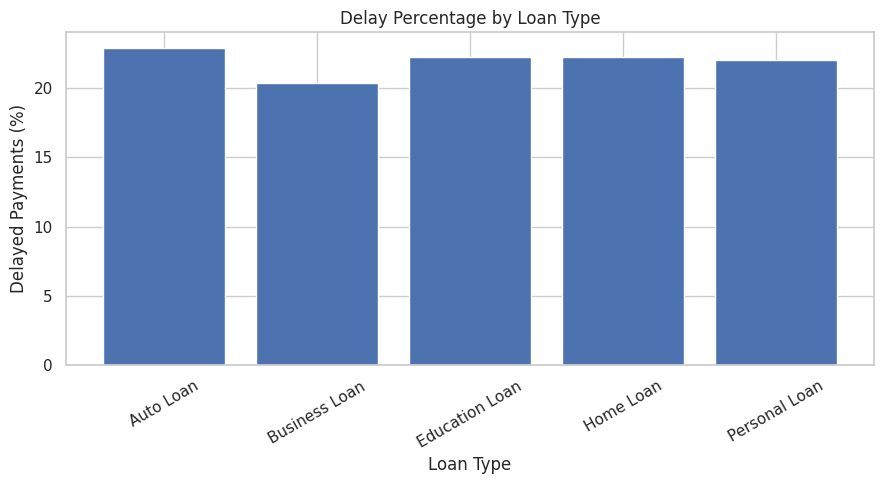

In [15]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.bar(
    risk_summary["loan_type"].astype(str),
    risk_summary["delay_percentage"]
)
plt.title("Delay Percentage by Loan Type")
plt.xlabel("Loan Type")
plt.ylabel("Delayed Payments (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


Repayment Risk by Income Band


,income_band,total_payments,delayed_payments,delay_percentage
0,High,996,176,17.67
1,Low,1644,436,26.52
2,Lower-Middle,1578,387,24.52
3,Unknown,288,44,15.28
4,Upper-Middle,1518,282,18.58


Repayment Risk by Occupation


,occupation,total_payments,delayed_payments,delay_percentage
0,Business,918,214,23.31
1,Contract,624,137,21.96
2,Retired,438,107,24.43
3,Salaried,2592,558,21.53
4,Self-Employed,1452,309,21.28


Repayment Risk by Loan Tenure


,tenure_group,total_payments,delayed_payments,delay_percentage
0,Up to 12,1158,242,20.90
1,13-36,2142,457,21.34
2,37-60,1254,285,22.73
3,61-120,1470,341,23.20


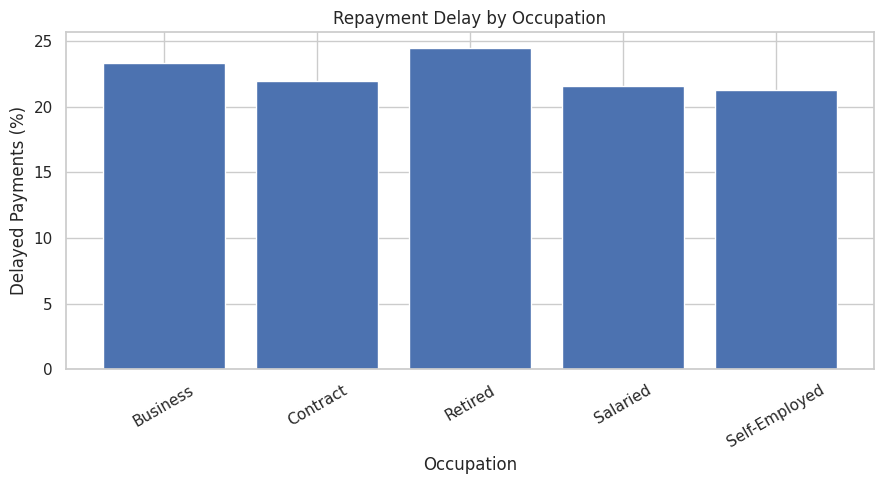

Step 4 completed successfully!


In [16]:

# Step 4: Analyze repayment risk by customer characteristics

import pandas as pd
import matplotlib.pyplot as plt

# Risk by income band
income_risk = portfolio.groupby("income_band", dropna=False).agg(
    total_payments=("payment_id", "count"),
    delayed_payments=("delayed_flag", "sum")
).reset_index()

income_risk["delay_percentage"] = (
    income_risk["delayed_payments"] /
    income_risk["total_payments"] * 100
).round(2)

print("Repayment Risk by Income Band")
display(income_risk)

# Risk by occupation
occupation_risk = portfolio.groupby("occupation", dropna=False).agg(
    total_payments=("payment_id", "count"),
    delayed_payments=("delayed_flag", "sum")
).reset_index()

occupation_risk["delay_percentage"] = (
    occupation_risk["delayed_payments"] /
    occupation_risk["total_payments"] * 100
).round(2)

print("Repayment Risk by Occupation")
display(occupation_risk)

# Risk by loan tenure
tenure_risk = portfolio.groupby("tenure_group", observed=False).agg(
    total_payments=("payment_id", "count"),
    delayed_payments=("delayed_flag", "sum")
).reset_index()

tenure_risk["delay_percentage"] = (
    tenure_risk["delayed_payments"] /
    tenure_risk["total_payments"] * 100
).round(2)

print("Repayment Risk by Loan Tenure")
display(tenure_risk)

# Visualize risk by occupation
plt.figure(figsize=(9, 5))
plt.bar(
    occupation_risk["occupation"].fillna("Unknown").astype(str),
    occupation_risk["delay_percentage"]
)
plt.title("Repayment Delay by Occupation")
plt.xlabel("Occupation")
plt.ylabel("Delayed Payments (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Save the analysis
income_risk.to_csv("/content/income_risk.csv", index=False)
occupation_risk.to_csv("/content/occupation_risk.csv", index=False)
tenure_risk.to_csv("/content/tenure_risk.csv", index=False)

print("Step 4 completed successfully!")


In [17]:

history_risk = portfolio.groupby(
    ["past_delays", "restructuring_flag"], dropna=False
).agg(
    total_payments=("payment_id", "count"),
    delayed_payments=("delayed_flag", "sum")
).reset_index()

history_risk["delay_percentage"] = (
    history_risk["delayed_payments"] /
    history_risk["total_payments"].replace(0, float("nan")) * 100
).round(2)

print("Repayment Risk by Previous History")
display(history_risk)

history_risk.to_csv("/content/history_risk.csv", index=False)


Repayment Risk by Previous History


,past_delays,restructuring_flag,total_payments,delayed_payments,delay_percentage
0,0,No,2304,430,18.66
1,0,Yes,294,78,26.53
2,1,No,2052,444,21.64
3,1,Yes,228,64,28.07
4,2,No,786,191,24.30
5,2,Yes,54,15,27.78
6,3,No,228,72,31.58
7,3,Yes,60,24,40.00
8,4,No,18,7,38.89


In [18]:

amount_risk = portfolio.groupby(
    "loan_amount_band", observed=False, dropna=False
).agg(
    total_payments=("payment_id", "count"),
    delayed_payments=("delayed_flag", "sum")
).reset_index()

amount_risk["delay_percentage"] = (
    amount_risk["delayed_payments"] /
    amount_risk["total_payments"].replace(0, float("nan")) * 100
).round(2)

print("Risk by Loan Amount")
display(amount_risk)

tenure_risk = portfolio.groupby(
    "tenure_group", observed=False, dropna=False
).agg(
    total_payments=("payment_id", "count"),
    delayed_payments=("delayed_flag", "sum")
).reset_index()

tenure_risk["delay_percentage"] = (
    tenure_risk["delayed_payments"] /
    tenure_risk["total_payments"].replace(0, float("nan")) * 100
).round(2)

print("Risk by Loan Tenure")
display(tenure_risk)


Risk by Loan Amount


,loan_amount_band,total_payments,delayed_payments,delay_percentage
0,Up to 25K,2952,639,21.65
1,25K-75K,2778,637,22.93
2,75K-150K,210,37,17.62
3,Above 150K,84,12,14.29


Risk by Loan Tenure


,tenure_group,total_payments,delayed_payments,delay_percentage
0,Up to 12,1158,242,20.90
1,13-36,2142,457,21.34
2,37-60,1254,285,22.73
3,61-120,1470,341,23.20


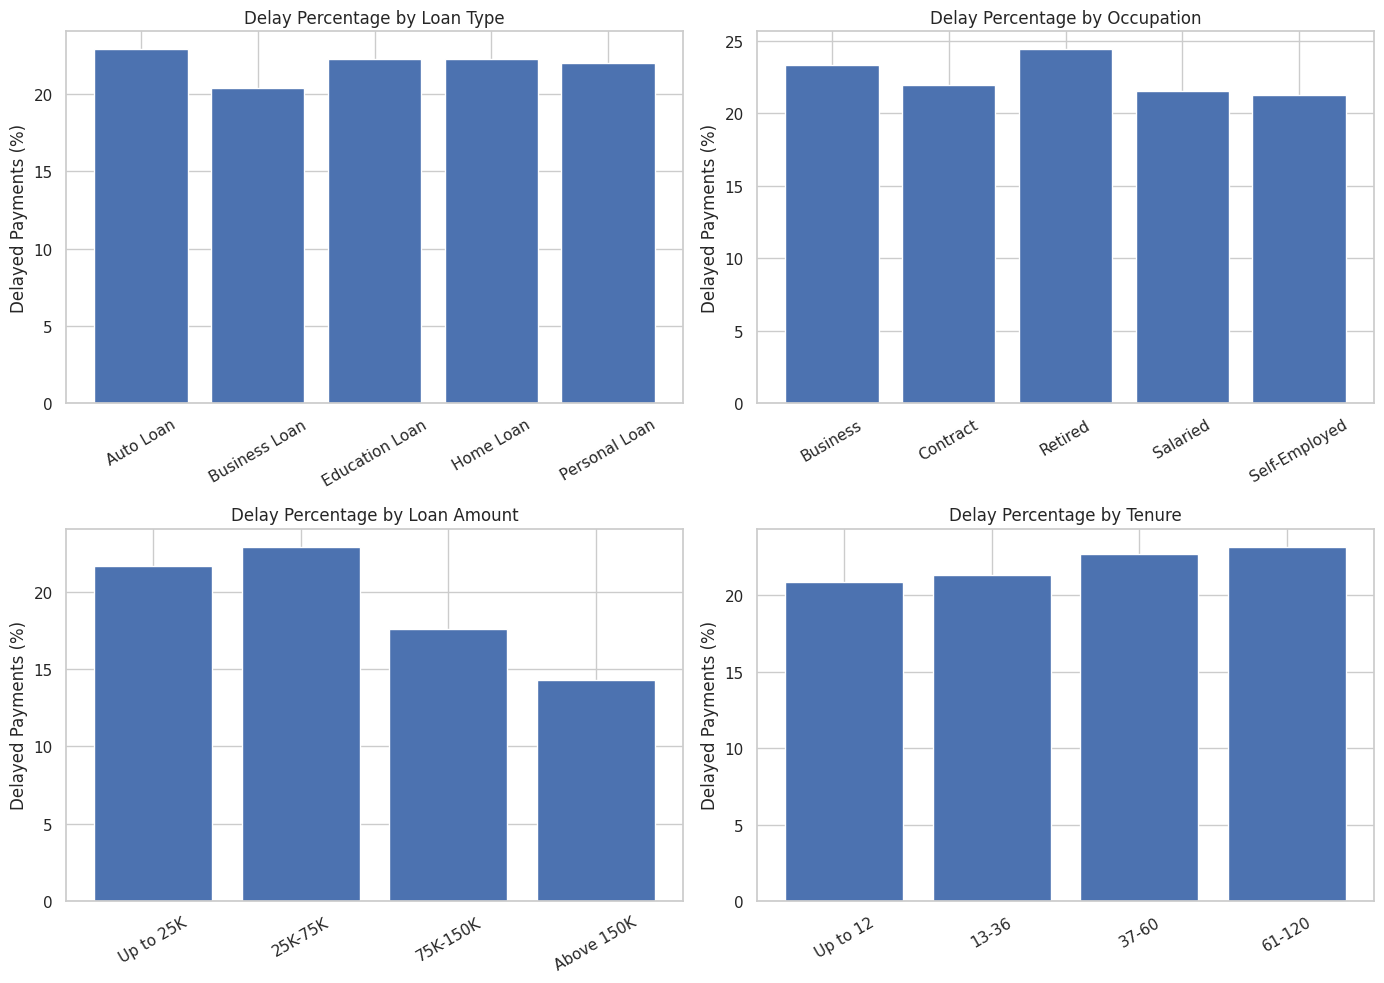

Dashboard saved successfully!


In [19]:

import matplotlib.pyplot as plt

fig, ax = plt.subplots(2, 2, figsize=(14, 10))

# Loan type
ax[0, 0].bar(
    risk_summary["loan_type"].astype(str),
    risk_summary["delay_percentage"]
)
ax[0, 0].set_title("Delay Percentage by Loan Type")
ax[0, 0].tick_params(axis="x", rotation=30)

# Occupation
ax[0, 1].bar(
    occupation_risk["occupation"].fillna("Unknown").astype(str),
    occupation_risk["delay_percentage"]
)
ax[0, 1].set_title("Delay Percentage by Occupation")
ax[0, 1].tick_params(axis="x", rotation=30)

# Loan amount
ax[1, 0].bar(
    amount_risk["loan_amount_band"].astype(str),
    amount_risk["delay_percentage"]
)
ax[1, 0].set_title("Delay Percentage by Loan Amount")
ax[1, 0].tick_params(axis="x", rotation=30)

# Tenure
ax[1, 1].bar(
    tenure_risk["tenure_group"].astype(str),
    tenure_risk["delay_percentage"]
)
ax[1, 1].set_title("Delay Percentage by Tenure")
ax[1, 1].tick_params(axis="x", rotation=30)

for a in ax.flat:
    a.set_ylabel("Delayed Payments (%)")
    a.set_xlabel("")

plt.tight_layout()
plt.savefig("/content/loan_portfolio_dashboard.png", dpi=200)
plt.show()

print("Dashboard saved successfully!")


In [20]:

print("KEY BUSINESS INSIGHTS")

if not risk_summary.empty:
    r = risk_summary.dropna(subset=["delay_percentage"])
    if not r.empty:
        row = r.loc[r["delay_percentage"].idxmax()]
        print(
            f"1. Highest delay percentage by loan type: "
            f"{row['loan_type']} ({row['delay_percentage']}%)."
        )

if not occupation_risk.empty:
    r = occupation_risk.dropna(subset=["delay_percentage"])
    if not r.empty:
        row = r.loc[r["delay_percentage"].idxmax()]
        print(
            f"2. Highest delay percentage by occupation: "
            f"{row['occupation']} ({row['delay_percentage']}%)."
        )

if not amount_risk.empty:
    r = amount_risk.dropna(subset=["delay_percentage"])
    if not r.empty:
        row = r.loc[r["delay_percentage"].idxmax()]
        print(
            f"3. Highest delay percentage by loan amount band: "
            f"{row['loan_amount_band']} ({row['delay_percentage']}%)."
        )

print(
    "4. Use these patterns to guide portfolio monitoring. "
    "Treat them as associations, not proof of causation."
)


KEY BUSINESS INSIGHTS
1. Highest delay percentage by loan type: Auto Loan (22.88%).
2. Highest delay percentage by occupation: Retired (24.43%).
3. Highest delay percentage by loan amount band: 25K-75K (22.93%).
4. Use these patterns to guide portfolio monitoring. Treat them as associations, not proof of causation.


In [21]:

with pd.ExcelWriter(
    "/content/Loan_Portfolio_Analysis_Final.xlsx",
    engine="openpyxl"
) as writer:
    portfolio.to_excel(
        writer, sheet_name="Cleaned Portfolio", index=False
    )
    risk_summary.to_excel(
        writer, sheet_name="Loan Type Risk", index=False
    )
    income_risk.to_excel(
        writer, sheet_name="Income Risk", index=False
    )
    occupation_risk.to_excel(
        writer, sheet_name="Occupation Risk", index=False
    )
    tenure_risk.to_excel(
        writer, sheet_name="Tenure Risk", index=False
    )
    amount_risk.to_excel(
        writer, sheet_name="Amount Risk", index=False
    )
    history_risk.to_excel(
        writer, sheet_name="History Risk", index=False
    )

print("Final Excel report created!")


Final Excel report created!


In [22]:

from google.colab import files

files.download("/content/Loan_Portfolio_Analysis_Final.xlsx")
files.download("/content/loan_portfolio_dashboard.png")



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>